In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RECORDS_FILE = "cohort_records.parquet"
FOLDS_FILE = "split_folds.json"
SPLIT_REPORT_FILE = "split_report.json"
SUPERCLASSES = ("NORM", "MI", "STTC", "CD", "HYP")
LIKELIHOOD_COLUMNS = tuple(f"likelihood_{superclass}" for superclass in SUPERCLASSES)
CERTAIN_LIKELIHOOD = 100
GROUP_COLUMN = "group_id"
TEST_FRACTION = 0.2
FOLD_COUNT = 5
PARTITION_NAMES = ("test",) + tuple(f"fold_{fold}" for fold in range(FOLD_COUNT))
PARTITION_FRACTIONS = (TEST_FRACTION,) + ((1 - TEST_FRACTION) / FOLD_COUNT,) * FOLD_COUNT
AGE_GROUP_EDGES = (18, 40, 60, 80, np.inf)
AGE_GROUP_LABELS = ("18-39", "40-59", "60-79", "80+")
MINOR_DEVICE_GROUPS = {"AT-6 C 5.0": "AT-6 C 5.x", "AT-6 C 5.3": "AT-6 C 5.x", "AT-6 C 5.6": "AT-6 C 5.x"}
OFFICIAL_TEST_FOLDS = (9, 10)
TOP_COMBINATION_COUNT = 12
RANDOM_SEED = 42
SEED_CANDIDATE_COUNT = 20
BASE_FIGURE_SIZE = (12, 5)
WIDE_FIGURE_SIZE = (18, 6)
TALL_FIGURE_SIZE = (12, 8)
SQUARE_FIGURE_SIZE = (9, 7)
FIGURE_DPI = 110
PRIMARY_COLOR = "#2E5E8C"
SECONDARY_COLOR = "#E07A5F"
NEUTRAL_COLOR = "#9AA5B1"
SEQUENTIAL_CMAP = "Blues"
SUPERCLASS_COLORS = {"NORM": "#4C9F70", "MI": "#D1495B", "STTC": "#EDAE49", "CD": "#00798C", "HYP": "#7B5EA7"}

In [3]:
class PlotTheme:
    @staticmethod
    def apply():
        sns.set_theme(style="whitegrid", context="notebook")
        plt.rcParams.update({
            "figure.figsize": BASE_FIGURE_SIZE,
            "figure.dpi": FIGURE_DPI,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.labelsize": 11,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "legend.frameon": False
        })

    @staticmethod
    def class_colors(labels):
        return [SUPERCLASS_COLORS.get(label, NEUTRAL_COLOR) for label in labels]

    @staticmethod
    def figure(nrows=1, ncols=1, size=BASE_FIGURE_SIZE, sharex=False, sharey=False):
        return plt.subplots(nrows, ncols, figsize=size, sharex=sharex, sharey=sharey, constrained_layout=True)

    @staticmethod
    def decorate(ax, title, xlabel=None, ylabel=None):
        ax.set_title(title)
        ax.set_xlabel(xlabel or "")
        ax.set_ylabel(ylabel or "")

PlotTheme.apply()

In [4]:
class CohortRepository:
    def __init__(self, processed_dir):
        self.processed_dir = processed_dir

    def load_records(self):
        return pd.read_parquet(self.processed_dir / RECORDS_FILE).set_index("ecg_id")

class StratificationColumns:
    @staticmethod
    def device_group(devices):
        return devices.replace(MINOR_DEVICE_GROUPS)

    @staticmethod
    def age_group(ages):
        return pd.cut(ages, bins=list(AGE_GROUP_EDGES), labels=list(AGE_GROUP_LABELS), right=False)

    @staticmethod
    def label_uncertain(records):
        return records[list(LIKELIHOOD_COLUMNS)].lt(CERTAIN_LIKELIHOOD).any(axis=1).astype(int)

    @staticmethod
    def uncertain_rate(records, superclass):
        return records.loc[records[superclass].eq(1), f"likelihood_{superclass}"].lt(CERTAIN_LIKELIHOOD).mean()

class StratificationTargets:
    @staticmethod
    def record_matrix(records):
        return pd.concat(
            [
                records[list(SUPERCLASSES)],
                pd.get_dummies(records["device_group"], prefix="device").astype(int),
                records[["label_uncertain"]],
                pd.get_dummies(records["age_group"], prefix="age").astype(int),
                records["sex"].rename("female")
            ],
            axis=1
        )

    @staticmethod
    def group_matrix(record_matrix, group_ids):
        return record_matrix.groupby(group_ids).sum()

In [5]:
class IterativeStratifier:
    def __init__(self, fractions, seed):
        self.fractions = np.asarray(fractions)
        self.rng = np.random.default_rng(seed)

    def rarest_label(self, targets, unassigned):
        remaining = targets[unassigned].sum(axis=0).astype(float)
        remaining[remaining == 0] = np.inf
        return int(self.rng.choice(np.flatnonzero(remaining == remaining.min())))

    def best_partition(self, label_need, size_need):
        candidates = np.flatnonzero(label_need == label_need.max())
        candidates = candidates[size_need[candidates] == size_need[candidates].max()]
        return int(self.rng.choice(candidates))

    def place(self, group, partition, assignment, targets, sizes, label_need, size_need):
        assignment[group] = partition
        label_need[partition] -= targets[group]
        size_need[partition] -= sizes[group]

    def assign(self, targets, sizes):
        label_need = np.outer(self.fractions, targets.sum(axis=0)).astype(float)
        size_need = self.fractions * sizes.sum()
        assignment = np.full(len(targets), -1)
        while (assignment < 0).any() and targets[assignment < 0].any():
            label = self.rarest_label(targets, assignment < 0)
            for group in self.rng.permutation(np.flatnonzero((assignment < 0) & (targets[:, label] > 0))):
                self.place(group, self.best_partition(label_need[:, label], size_need), assignment, targets, sizes, label_need, size_need)
        for group in self.rng.permutation(np.flatnonzero(assignment < 0)):
            self.place(group, int(np.argmax(size_need)), assignment, targets, sizes, label_need, size_need)
        return assignment

class SplitAuditor:
    def __init__(self, record_matrix, partitions, group_ids):
        self.record_matrix = record_matrix
        self.partitions = partitions
        self.group_ids = group_ids

    def columns_like(self, prefix):
        return [column for column in self.record_matrix.columns if column.startswith(prefix)]

    def leaking_groups(self):
        return int(self.partitions.groupby(self.group_ids).nunique().gt(1).sum())

    def sizes(self):
        return pd.DataFrame({
            "records": self.partitions.value_counts().reindex(PARTITION_NAMES),
            "groups": self.group_ids.groupby(self.partitions).nunique().reindex(PARTITION_NAMES),
            "record_share": self.partitions.value_counts(normalize=True).reindex(PARTITION_NAMES) * 100
        })

    def shares(self, columns):
        return self.record_matrix[columns].groupby(self.partitions).mean().reindex(PARTITION_NAMES) * 100

    def max_deviation(self):
        return (self.shares(list(self.record_matrix.columns)) - self.record_matrix.mean() * 100).abs().max().sort_values(ascending=False)

    def positives(self):
        return self.record_matrix[list(SUPERCLASSES)].groupby(self.partitions).sum().reindex(PARTITION_NAMES)

    def combination_shares(self, top_count):
        combinations = self.record_matrix[list(SUPERCLASSES)].apply(lambda row: "+".join(row.index[row.eq(1)]), axis=1)
        top_combinations = combinations.value_counts().head(top_count).index
        return pd.crosstab(self.partitions, combinations, normalize="index").reindex(index=PARTITION_NAMES, columns=top_combinations) * 100

class PartitionSearch:
    def __init__(self, records, record_targets):
        self.records = records
        self.record_targets = record_targets
        self.group_targets = StratificationTargets.group_matrix(record_targets, records[GROUP_COLUMN])
        self.group_sizes = records.groupby(GROUP_COLUMN).size().reindex(self.group_targets.index)

    def partitions(self, seed):
        assignment = IterativeStratifier(PARTITION_FRACTIONS, seed).assign(self.group_targets.to_numpy(), self.group_sizes.to_numpy())
        return self.records[GROUP_COLUMN].map(pd.Series(np.array(PARTITION_NAMES)[assignment], index=self.group_targets.index))

    def worst_deviation(self, seed):
        return SplitAuditor(self.record_targets, self.partitions(seed), self.records[GROUP_COLUMN]).max_deviation().max()

    def scores(self, seeds):
        return pd.Series({seed: self.worst_deviation(seed) for seed in seeds})

class SplitWriter:
    def __init__(self, directory):
        self.directory = directory

    def write(self, file_name, payload):
        (self.directory / file_name).write_text(json.dumps(payload, indent=2))

    @staticmethod
    def folds_payload(partitions, stratify_on, seed):
        return {
            "seed": seed,
            "test_fraction": TEST_FRACTION,
            "fold_count": FOLD_COUNT,
            "group_column": GROUP_COLUMN,
            "stratify_on": stratify_on,
            "test": partitions.index[partitions.eq("test")].tolist(),
            "folds": {str(fold): partitions.index[partitions.eq(f"fold_{fold}")].tolist() for fold in range(FOLD_COUNT)}
        }

    @staticmethod
    def report_payload(auditor, seed_scores):
        return {
            "seed_scores_pp": seed_scores.round(3).to_dict(),
            "leaking_groups": auditor.leaking_groups(),
            "sizes": auditor.sizes().round(2).to_dict(orient="index"),
            "max_deviation_pp": auditor.max_deviation().round(3).to_dict(),
            "superclass_share": auditor.shares(list(SUPERCLASSES)).round(2).to_dict(orient="index"),
            "superclass_positives": auditor.positives().to_dict(orient="index")
        }

In [6]:
class Charts:
    @staticmethod
    def bar(
        series,
        title,
        xlabel=None,
        ylabel="Count",
        color=PRIMARY_COLOR,
        horizontal=False,
        size=BASE_FIGURE_SIZE,
        rotation=0,
        value_format="%d",
        annotate=True
    ):
        _, ax = PlotTheme.figure(size=size)
        labels = series.index.astype(str)
        bars = ax.barh(labels, series.values, color=color) if horizontal else ax.bar(labels, series.values, color=color)
        if horizontal:
            ax.invert_yaxis()
        ax.tick_params(axis="x", rotation=rotation)
        if annotate:
            ax.bar_label(bars, fmt=value_format, padding=2, fontsize=9)
        PlotTheme.decorate(ax, title, ylabel if horizontal else xlabel, xlabel if horizontal else ylabel)
        plt.show()

    @staticmethod
    def heatmap(matrix, title, value_format="d", size=SQUARE_FIGURE_SIZE, cmap=SEQUENTIAL_CMAP):
        _, ax = PlotTheme.figure(size=size)
        sns.heatmap(matrix, annot=True, fmt=value_format, cmap=cmap, linewidths=0.5, ax=ax)
        PlotTheme.decorate(ax, title)
        plt.show()

    @staticmethod
    def grouped_bar(frame, title, xlabel, ylabel, colors=None, size=BASE_FIGURE_SIZE, rotation=0):
        _, ax = PlotTheme.figure(size=size)
        frame.plot(kind="bar", color=colors, width=0.8, ax=ax)
        ax.tick_params(axis="x", rotation=rotation)
        ax.axhline(0, color=NEUTRAL_COLOR, linewidth=0.8)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

In [7]:
records = CohortRepository(PROCESSED_DATA_DIR).load_records()
print(f"records: {len(records)} | groups: {records[GROUP_COLUMN].nunique()} | patients: {records['patient_id'].nunique()}")

records: 21254 | groups: 18499 | patients: 18499


In [8]:
records["device_group"] = StratificationColumns.device_group(records["device"])
records["age_group"] = StratificationColumns.age_group(records["age"])
records["label_uncertain"] = StratificationColumns.label_uncertain(records)

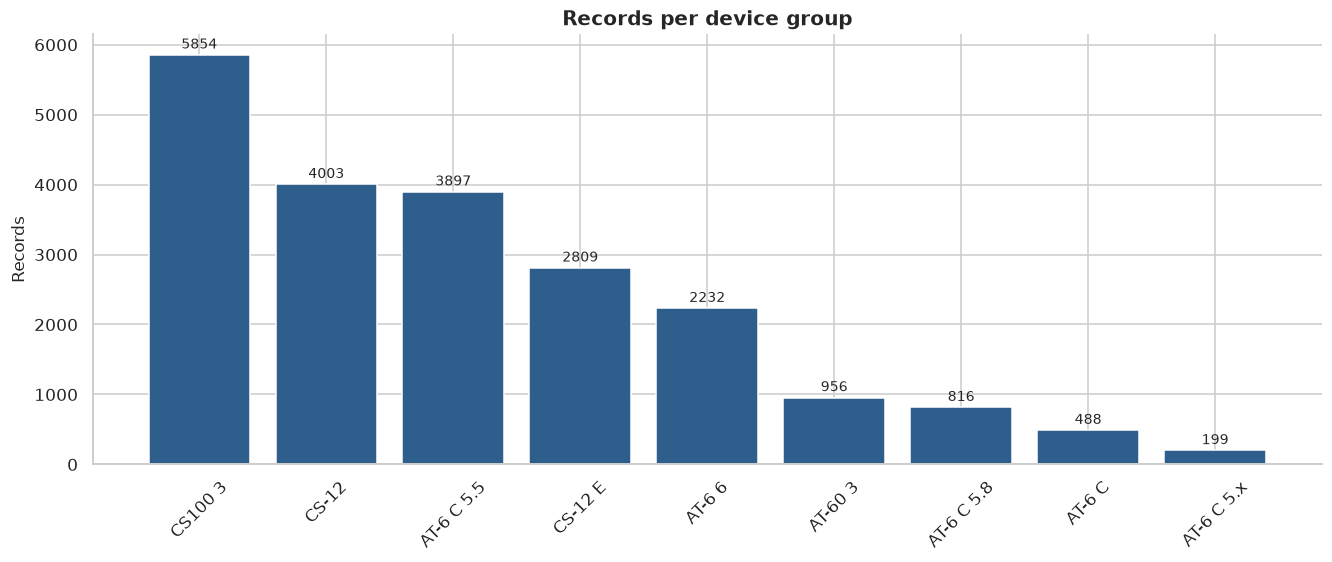

In [9]:
Charts.bar(records["device_group"].value_counts(), "Records per device group", ylabel="Records", rotation=45)

records with an uncertain label: 30.2%


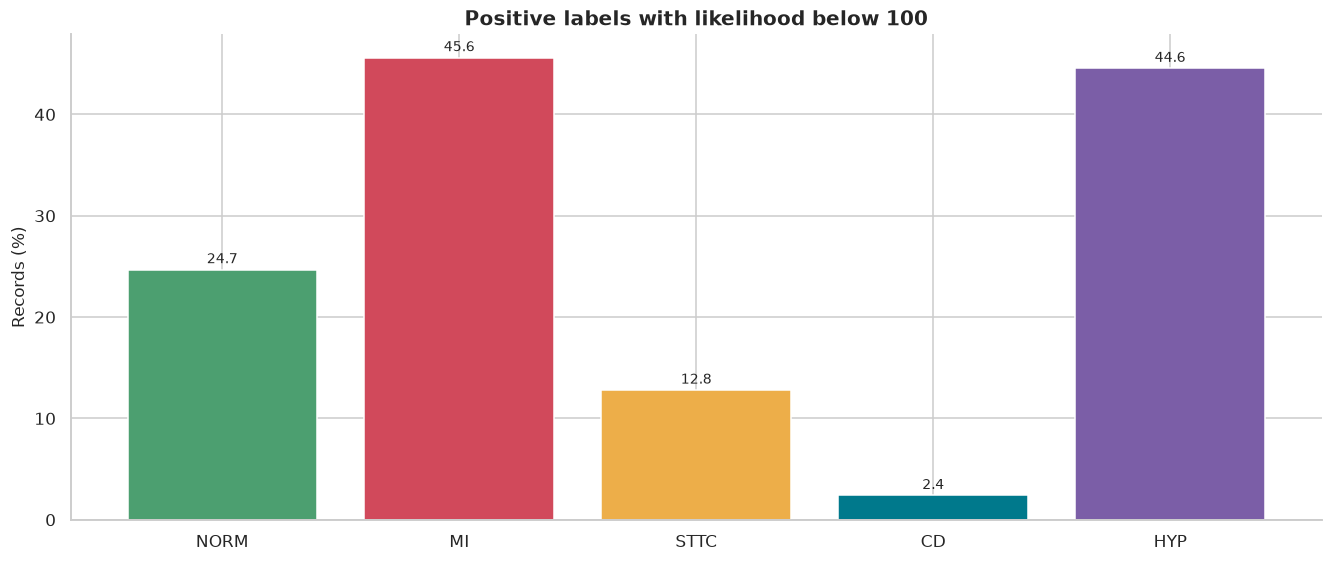

In [10]:
uncertain_by_superclass = pd.Series({superclass: StratificationColumns.uncertain_rate(records, superclass) for superclass in SUPERCLASSES})
print(f"records with an uncertain label: {records['label_uncertain'].mean():.1%}")
Charts.bar(uncertain_by_superclass * 100, f"Positive labels with likelihood below {CERTAIN_LIKELIHOOD}", ylabel="Records (%)", color=PlotTheme.class_colors(SUPERCLASSES), value_format="%.1f")

In [11]:
record_targets = StratificationTargets.record_matrix(records)
partition_search = PartitionSearch(records, record_targets)
print(f"record targets: {record_targets.shape} | group targets: {partition_search.group_targets.shape}")

record targets: (21254, 20) | group targets: (18499, 20)


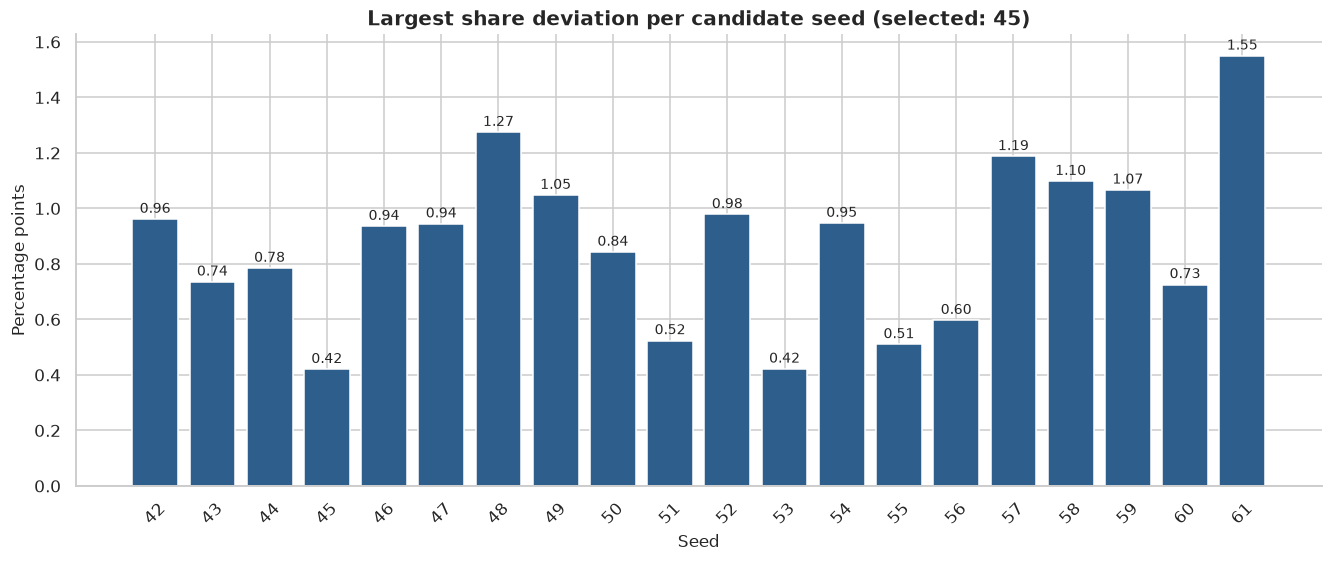

In [12]:
seed_scores = partition_search.scores(range(RANDOM_SEED, RANDOM_SEED + SEED_CANDIDATE_COUNT))
best_seed = int(seed_scores.idxmin())
Charts.bar(seed_scores, f"Largest share deviation per candidate seed (selected: {best_seed})", xlabel="Seed", ylabel="Percentage points", value_format="%.2f", rotation=45)

In [13]:
records["partition"] = partition_search.partitions(best_seed)
auditor = SplitAuditor(record_targets, records["partition"], records[GROUP_COLUMN])
assert auditor.leaking_groups() == 0 and records["partition"].notna().all()
auditor.sizes().round(2)

,records,groups,record_share
partition,,,
test,4250,3699,20.00
fold_0,3401,2955,16.00
fold_1,3401,2982,16.00
fold_2,3402,2956,16.01
fold_3,3400,2948,16.00
fold_4,3400,2959,16.00


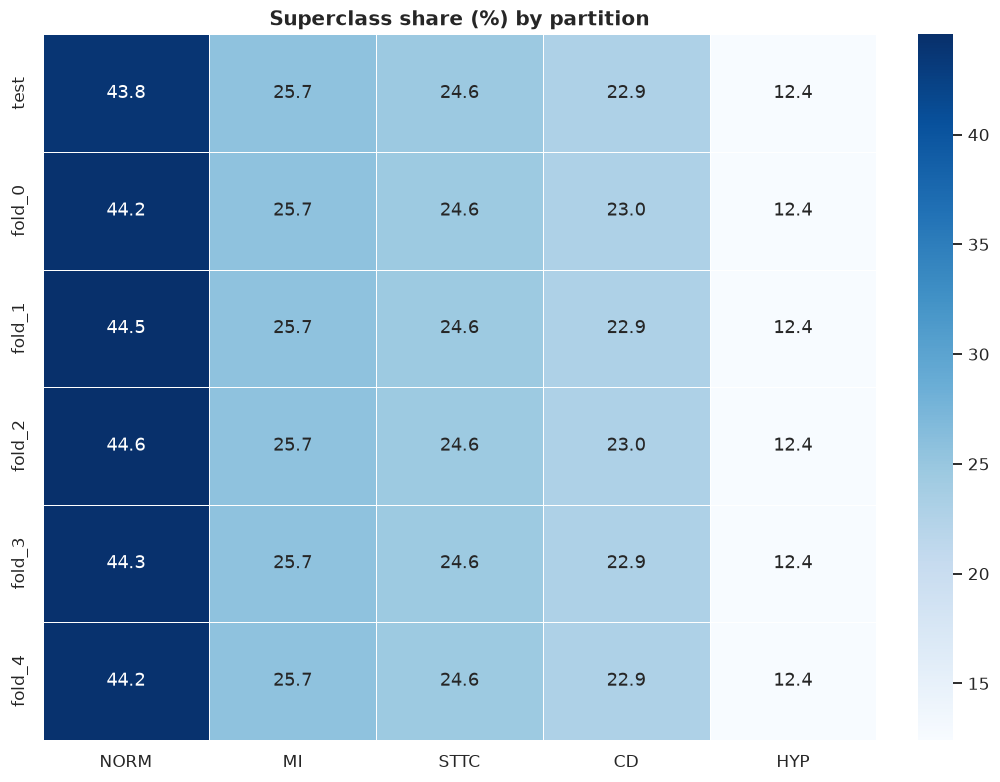

In [14]:
Charts.heatmap(auditor.shares(list(SUPERCLASSES)), "Superclass share (%) by partition", value_format=".1f")

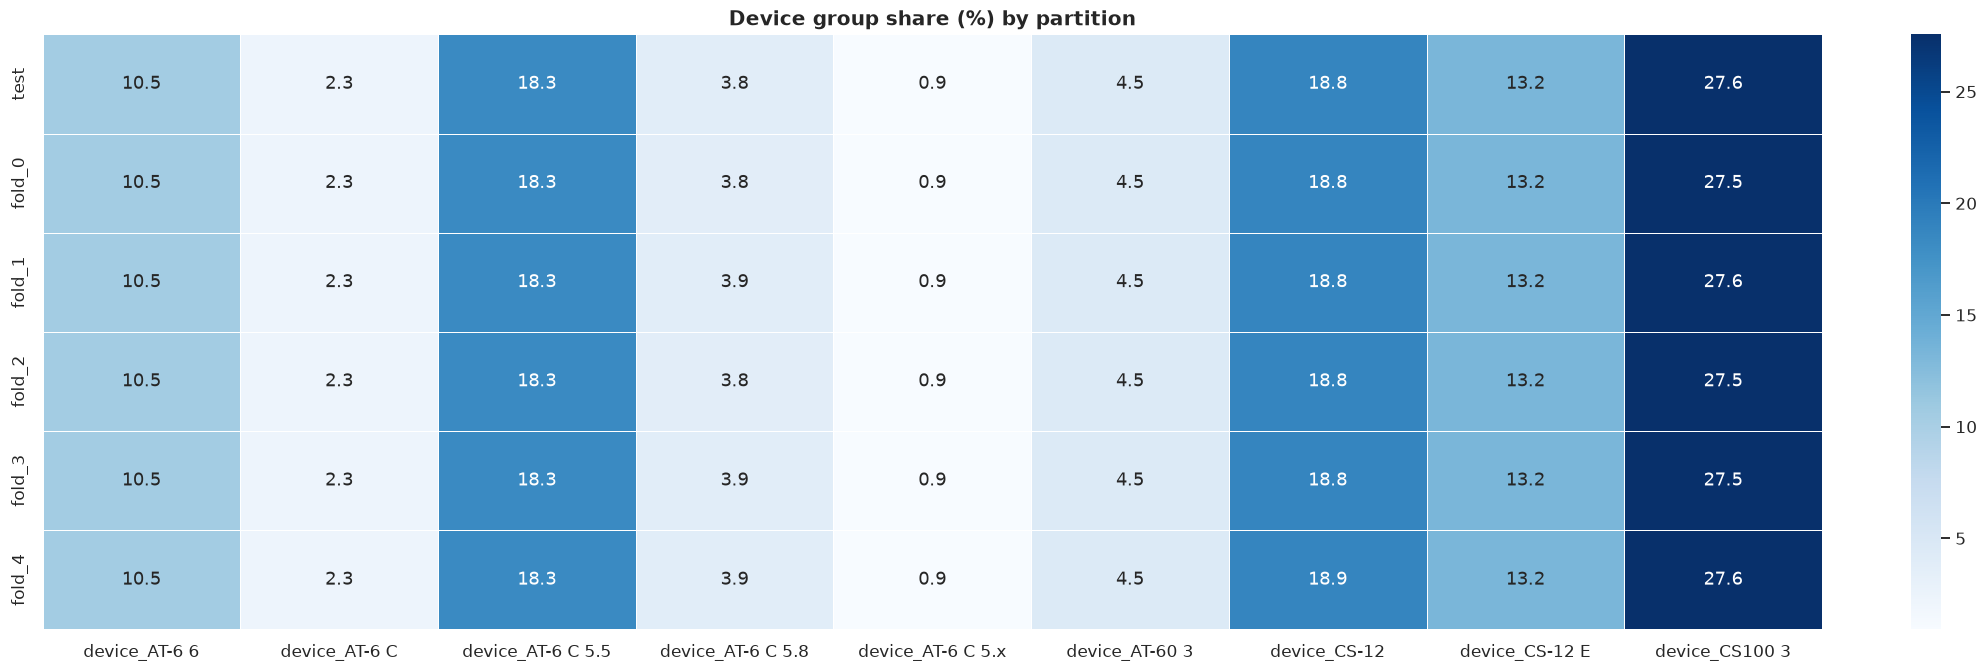

In [15]:
Charts.heatmap(auditor.shares(auditor.columns_like("device_")), "Device group share (%) by partition", value_format=".1f", size=WIDE_FIGURE_SIZE)

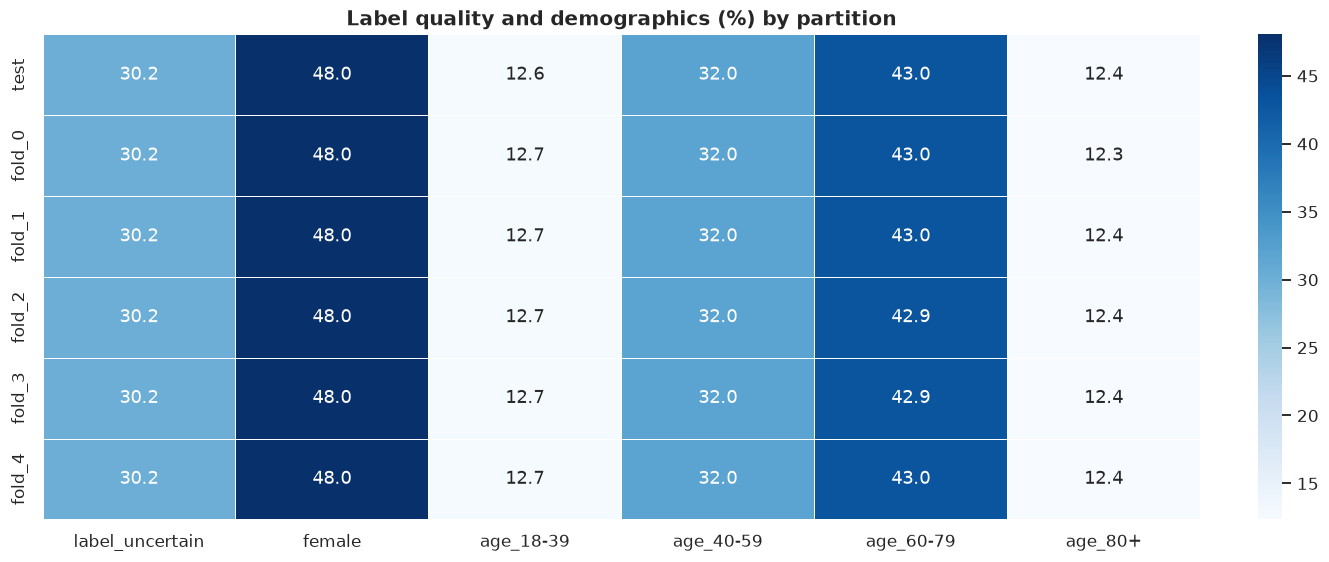

In [16]:
Charts.heatmap(auditor.shares(["label_uncertain", "female"] + auditor.columns_like("age_")), "Label quality and demographics (%) by partition", value_format=".1f", size=BASE_FIGURE_SIZE)

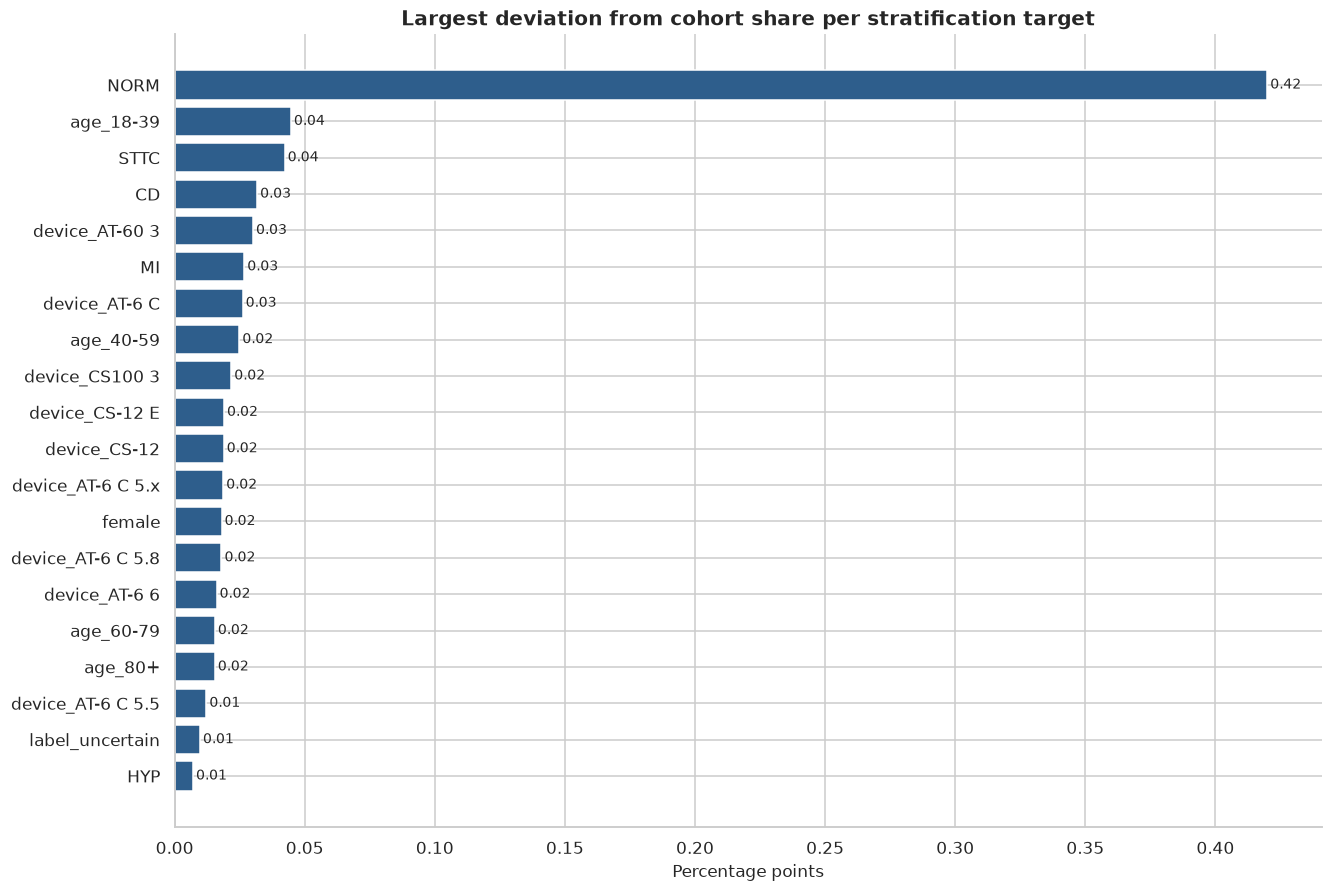

In [17]:
Charts.bar(auditor.max_deviation(), "Largest deviation from cohort share per stratification target", ylabel="Percentage points", horizontal=True, size=TALL_FIGURE_SIZE, value_format="%.2f")

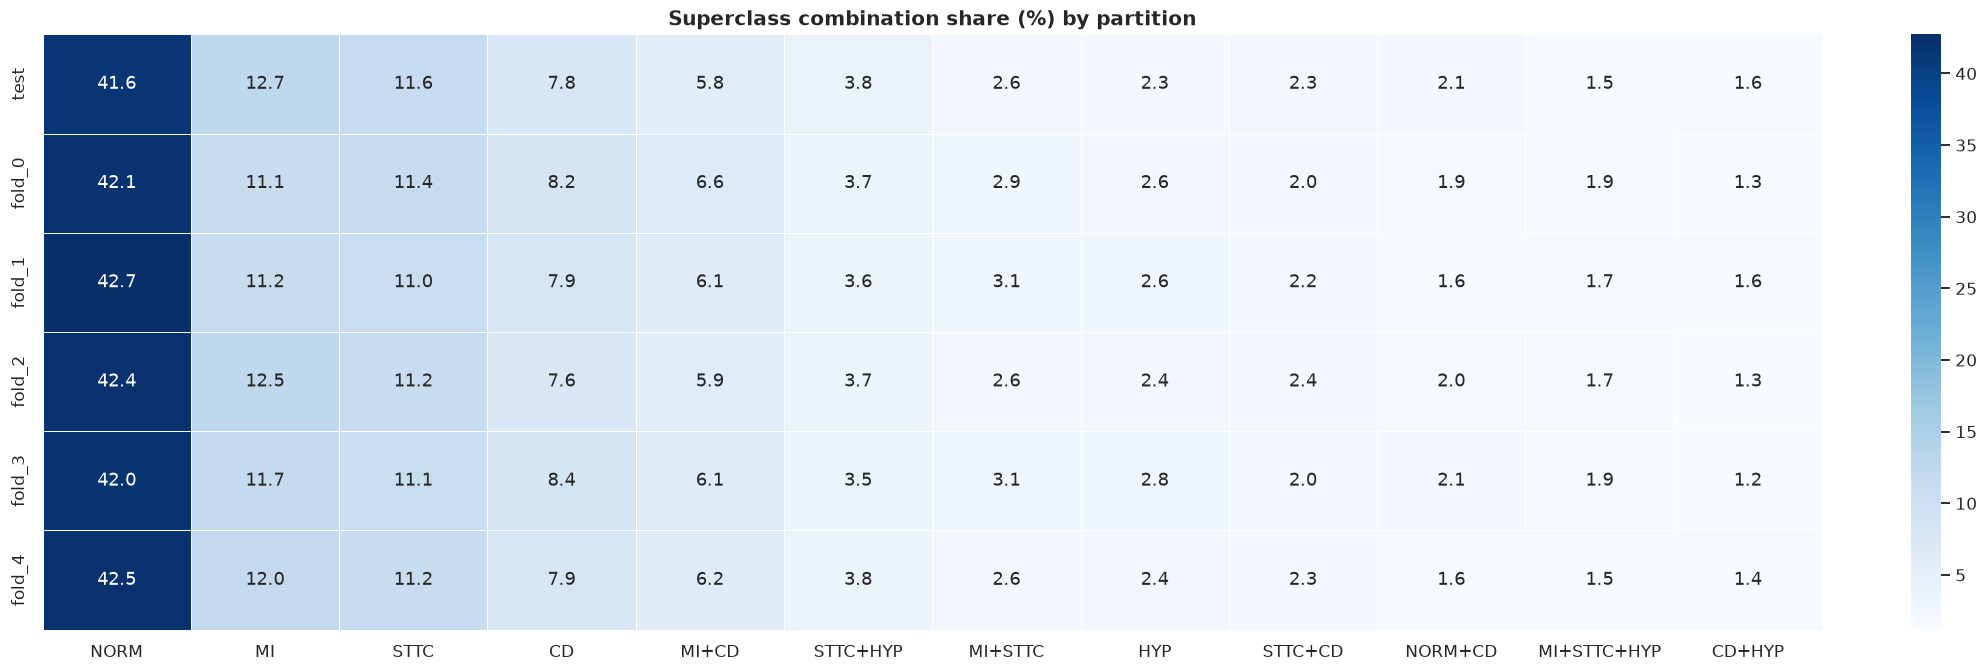

In [18]:
Charts.heatmap(auditor.combination_shares(TOP_COMBINATION_COUNT), "Superclass combination share (%) by partition", value_format=".1f", size=WIDE_FIGURE_SIZE)

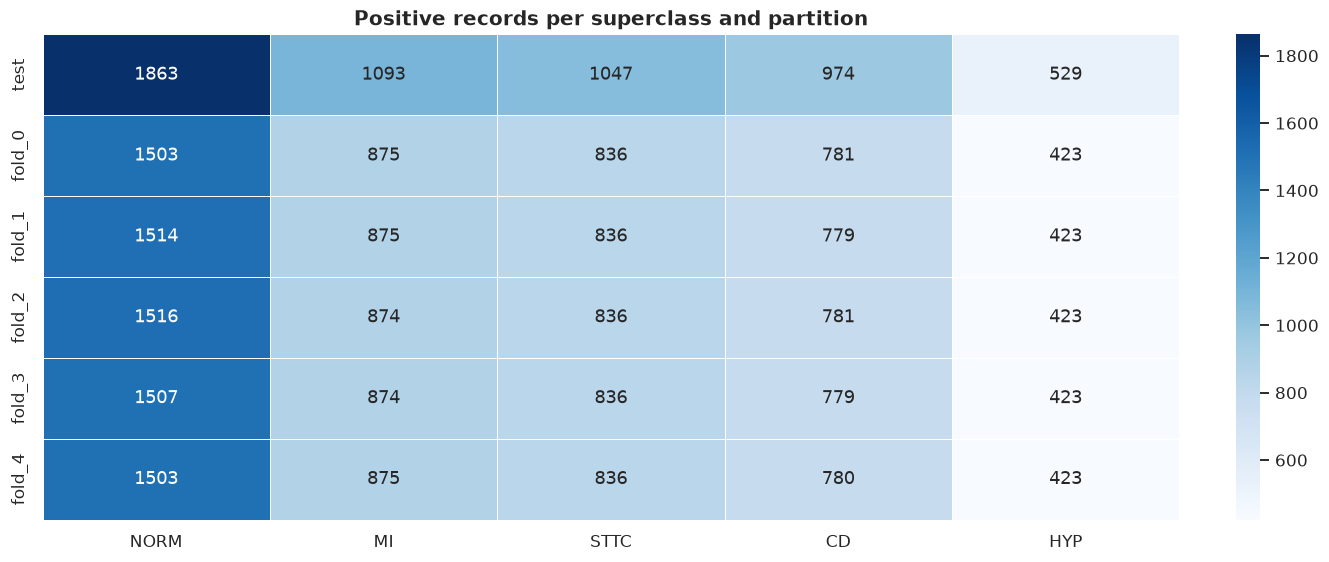

In [19]:
Charts.heatmap(auditor.positives(), "Positive records per superclass and partition", size=BASE_FIGURE_SIZE)

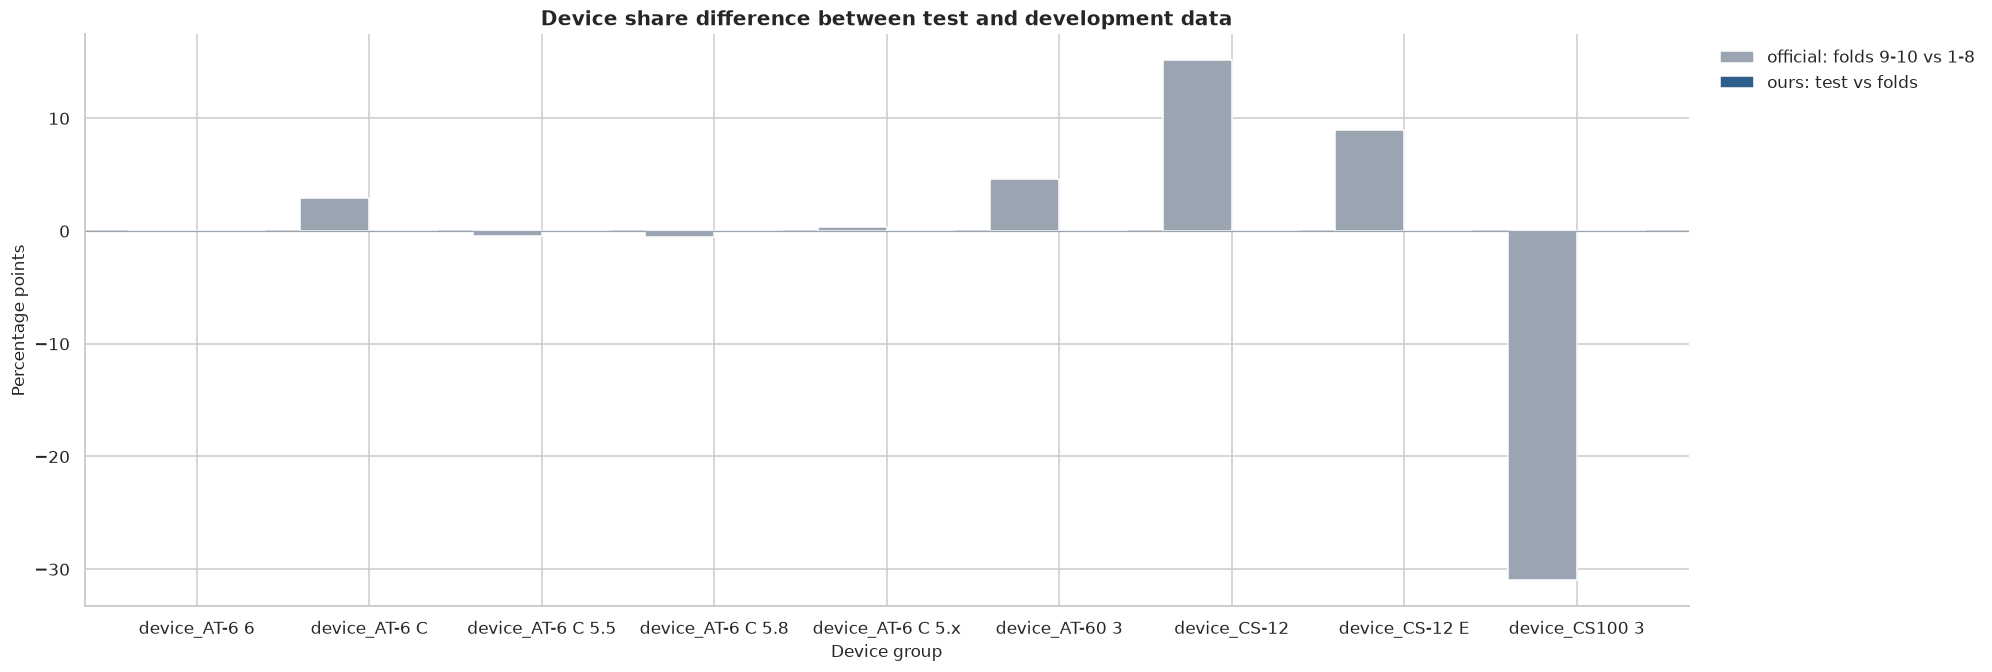

In [20]:
official_test = records["strat_fold"].isin(OFFICIAL_TEST_FOLDS)
our_test = records["partition"].eq("test")
device_columns = auditor.columns_like("device_")
device_shift = pd.DataFrame({
    "official: folds 9-10 vs 1-8": (record_targets.loc[official_test, device_columns].mean() - record_targets.loc[~official_test, device_columns].mean()) * 100,
    "ours: test vs folds": (record_targets.loc[our_test, device_columns].mean() - record_targets.loc[~our_test, device_columns].mean()) * 100
})
Charts.grouped_bar(device_shift, "Device share difference between test and development data", "Device group", "Percentage points", colors=[NEUTRAL_COLOR, PRIMARY_COLOR], size=WIDE_FIGURE_SIZE)

In [21]:
split_writer = SplitWriter(PROCESSED_DATA_DIR)
split_writer.write(FOLDS_FILE, SplitWriter.folds_payload(records["partition"], list(record_targets.columns), best_seed))

In [22]:
split_report = SplitWriter.report_payload(auditor, seed_scores)
split_writer.write(SPLIT_REPORT_FILE, split_report)
split_report["max_deviation_pp"]

{'NORM': 0.42,
 'age_18-39': 0.045,
 'STTC': 0.042,
 'CD': 0.032,
 'device_AT-60 3': 0.03,
 'MI': 0.027,
 'device_AT-6 C': 0.026,
 'age_40-59': 0.025,
 'device_CS100 3': 0.022,
 'device_CS-12 E': 0.019,
 'device_CS-12': 0.019,
 'device_AT-6 C 5.x': 0.019,
 'female': 0.018,
 'device_AT-6 C 5.8': 0.018,
 'device_AT-6 6': 0.016,
 'age_60-79': 0.015,
 'age_80+': 0.015,
 'device_AT-6 C 5.5': 0.012,
 'label_uncertain': 0.01,
 'HYP': 0.007}